In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import csv
from datetime import datetime, timezone, timedelta
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

# Data merging
We have to combine the two datasets that are the price data and the weather data

In [2]:
infile_price  = open("price_data.csv", "r")
reader_price = csv.reader(infile_price)
infile_weather = open("weather_data.csv", "r")
reader_weather = csv.reader(infile_weather)

price_list= []
weather_list = []
for line in reader_price:
    price_list.append([[int(line[0]),float(line[1])]])
for line in reader_weather:
    if len(line)==7:
        weather_list.append([[int(line[0])]+[ float(item) for item in line[1:] ]])
infile_price.close()
infile_weather.close()

We will check the last timestamp for weather and price data. We always need to make sure, weather data is more recent than price data

In [3]:
print(datetime.utcfromtimestamp(price_list[-1][0][0]/1000))

2026-08-30 21:00:00


In [4]:
print(datetime.utcfromtimestamp(weather_list[-1][0][0]/1000))

2026-09-01 23:00:00


Instead of just filtering for the times to correspond to each other, I will include the dates from which on both weather and price data are available. In order to make a combined tensor of price and weather I will then use the closest time stammp weather data after that time

In [5]:
min_time = max(weather_list[0][0][0], price_list[0][0][0])
max_time = min(weather_list[-1][0][0], price_list[-1][0][0])

#Delete anything that happened before min_time and anything that happened after max_time
for index, line in enumerate(price_list):
    if line[0][0]<min_time or line[0][0]>max_time:
        price_list.pop(index)
for index, line in enumerate(weather_list):
    if line[0][0]<min_time or line[0][0]>max_time:
        weather_list.pop(index)

# Now add the weather data into the price list, taking the time stamp that comes directly after the price timestamp
last_weather_index= 0 
for i,line in enumerate(price_list):
    if len(line[0])>2:
        raise ValueError("The lists have already been merged")
    if last_weather_index == len(weather_list)-1:
        print('WARNING: Weather data may not go as far as electricity price data')
    if i%1000 == 0:
        print("progress: "+str(i)+"/"+str(len(price_list)//1000*1000),end="\r")
    timestamp = line[0][0]
    # The search will start from the place in the list where the last time stamp was found (last_weather_index) and find the next timestamp over our timestamp
    for j,weather_line in enumerate(weather_list[last_weather_index:]): 
        if weather_line[0][0] >= timestamp:
            break
    last_weather_index = last_weather_index + j
    for value in weather_line[0][1:]:
        line[0].append(value)

progress: 40000/40000

Now that we have the weather data in the price list, let's expand the timestamp as year, month, day, hour

In [6]:
for line in price_list:
    timestamp = line[0][0]
    line[0].pop(0)
    time_object = datetime.utcfromtimestamp(timestamp/1000)
    year = int(time_object.year)
    line[0].insert(0,year)
    month = int(time_object.month)
    line[0].insert(1,month)
    day = int(time_object.day)
    line[0].insert(2,day)
    hour = int(time_object.hour)
    line[0].insert(3,hour)
price_list

[[[2022, 1, 2, 23, 0.31, 0.0, 0.0, 0.0, 39.28456, 45.218353, 27.438046]],
 [[2022, 1, 3, 0, -0.01, 0.0, 0.0, 0.0, 44.477123, 41.699436, 21.892027]],
 [[2022, 1, 3, 1, -0.07, 0.0, 0.0, 0.0, 43.96129, 40.076588, 21.096123]],
 [[2022, 1, 3, 2, -1.05, 0.0, 0.0, 0.0, 43.77369, 38.941616, 28.291512]],
 [[2022, 1, 3, 3, -1.0, 0.0, 0.0, 0.0, 41.638786, 39.658867, 34.627434]],
 [[2022, 1, 3, 4, 0.32, 0.0, 0.0, 0.0, 38.48129, 40.52839, 38.479603]],
 [[2022, 1, 3, 5, 37.55, 0.0, 0.0, 0.0, 37.834267, 39.39986, 40.257275]],
 [[2022, 1, 3, 6, 88.76, 0.0, 0.0, 0.0, 39.081146, 38.48129, 42.242897]],
 [[2022, 1, 3, 7, 122.93, 0.0, 0.0, 0.0, 39.047966, 36.30471, 39.619625]],
 [[2022, 1, 3, 8, 110.17, 10.0, 6.0, 1.0, 39.8447, 35.747112, 41.514103]],
 [[2022, 1, 3, 9, 93.38, 57.0, 49.0, 16.0, 37.372437, 34.65175, 41.23532]],
 [[2022, 1, 3, 10, 90.73, 112.0, 80.0, 67.0, 33.636406, 34.06521, 43.063282]],
 [[2022, 1, 3, 11, 82.37, 92.0, 135.0, 68.0, 32.682762, 38.183765, 41.742928]],
 [[2022, 1, 3, 12, 80.9,

As we can see, the price_list contains
[year, month, day, hour, price, sunlight, sunlight, sunlight, wind, wind ,wind]

In [7]:
price_list[0],price_list[-1]

([[2022, 1, 2, 23, 0.31, 0.0, 0.0, 0.0, 39.28456, 45.218353, 27.438046]],
 [[2026, 8, 30, 21, 168.79, 0.0, 0.0, 0.0, 19.800817, 18.745079, 18.201374]])

In [8]:
price_data_tensor = torch.tensor(price_list)
#only_the_prices = price_data_tensor[:,:,4:5]
#only_the_weather = torch.cat((price_data_tensor[:,:,:4],price_data_tensor[:,:,5:]),dim=2)

# Normalizing Electricity prices
We need electricity prices between zero and one and not between -500 and 1000. Thus we will define a normalize and a de_normalize function for electricity prices (and only the prices)

In [9]:
MIN_PRICE = float(min(price_data_tensor[:,:,4:5]))
MAX_PRICE = float(max(price_data_tensor[:,:,4:5]))
MIN_PRICE,MAX_PRICE

(-500.0, 936.280029296875)

In [10]:
def normalize_price(raw_price):
    '''
    normalizes prices in torch tensors of any shape using the global variables MIN_PRICE and MAX_PRICE
    '''
    shape = torch.ones(raw_price.shape)
    multiplier = 1/(MAX_PRICE-MIN_PRICE) * shape
    adder = MIN_PRICE * shape
    return (raw_price-adder)*multiplier
#let's do an easy test
normalize_price(torch.tensor([[1000,1000,1000],[-500,-500,-500]]))

tensor([[1.0444, 1.0444, 1.0444],
        [0.0000, 0.0000, 0.0000]])

In [11]:
def de_normalize_price(normalized_price):
    '''
    de-normalizes prices in torch tensors of any shape
    '''
    shape = torch.ones(normalized_price.shape)
    multiplier = (MAX_PRICE-MIN_PRICE) * shape
    adder = MIN_PRICE * shape
    return (normalized_price*multiplier)+adder

#let's do an easy test
de_normalize_price(torch.tensor([[1,1,1],[0,0,0]]))

tensor([[ 936.2800,  936.2800,  936.2800],
        [-500.0000, -500.0000, -500.0000]])

In [12]:
normalize_price(de_normalize_price(torch.tensor([[1,1,1],[0,0,0]])))

tensor([[1., 1., 1.],
        [0., 0., 0.]])

In [13]:
de_normalize_price(normalize_price(torch.tensor([[1,1,1],[0,0,0]])))

tensor([[1.0000e+00, 1.0000e+00, 1.0000e+00],
        [3.0518e-05, 3.0518e-05, 3.0518e-05]])

# Putting the data day-wise
I need to put the data together per day

In [14]:
day_number = len(price_data_tensor)//24
day_number

1700

In [15]:
def make_daywise(the_tensor):
    the_elements = len(the_tensor[0,0])
    zahl_tage = int(len(the_tensor)/(24))
    if not zahl_tage*24 == len(the_tensor):
        print("Warning, the number of hours is not a multiple of 24")
        the_tensor = the_tensor[:zahl_tage*24]
    b = the_tensor.transpose(0,2)
    c = b.reshape(the_elements,zahl_tage,24)
    d = c.transpose(0,1)
    e = d.reshape(zahl_tage,1,the_elements*24)
    return e

In [16]:
#let's test the make daywise function
test_list = []
for i in range(24):
    test_list.append([[2022,1,1,i,-10+0.1*i,20,30,40]])
test_tensor = torch.tensor(test_list)
make_daywise(test_tensor)

tensor([[[ 2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1

In [17]:
price_data_daywise = make_daywise(price_data_tensor)
price_data_daywise[0], price_data_daywise.shape

Warning, the number of hours is not a multiple of 24


(tensor([[ 2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,
           2.0220e+03,  2.0220e+03,  2.0220e+03,  2.0220e+03,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,  1.0000e+00,
           1.0000e+00,  1.0000e+00,  1.0000e+00,  2.0000e+00,  3.0000e+00,
           3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,
           3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,
           3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,  3.0000e+00,
           3.0000e+00,  3

So far the tensor starts with the year 24 times, the month 24 times, the day 24 times and the times we will cut the redundant part away. We take the 3rd entry for the date, because during summer time midnight is UTC 22:00 and thus the previous day. Therefore taking the third date of the day gives the correct date

In [18]:
def remove_unnecessary_date(X):
    return torch.cat((X[:,:,2:3],X[:,:,2+24:3+24],X[:,:,2+2*24:3+2*24],X[:,:,4*24:]),dim=-1)
price_data_daywise_better = remove_unnecessary_date(price_data_daywise)
number_datap_days= len(price_data_daywise_better)

# Putting (normalized) weather differences in the weather coorddinates

In [19]:
cutting_index = max(int(number_datap_days/4*3),number_datap_days-365)
#In order to have sensible amounts, I divide by 1000 and add 500. This way all the weather data is between 0 and 1
weather_differences = (price_data_daywise_better[1:,0,3+24:]-price_data_daywise_better[:-1,0,3+24:])/1000+0.5
dates_prices_only = price_data_daywise_better[:,0,:3+24]

## Normalizing the data

In [20]:
dates_prices_normalized = torch.cat((dates_prices_only[:,:1]/10000,dates_prices_only[:,1:3]/100, normalize_price(dates_prices_only[:,3:])),-1 )

In [21]:
price_and_differences = torch.cat((dates_prices_normalized[:-1],weather_differences),dim=-1)
training_data=price_and_differences[:cutting_index]
training_targets=dates_prices_normalized[1:cutting_index+1,3:]
evaluation_data=price_and_differences[cutting_index:]
evaluation_targets=dates_prices_normalized[cutting_index+1:,3:]
training_data.shape, training_targets.shape, evaluation_data.shape, evaluation_targets.shape

(torch.Size([1335, 171]),
 torch.Size([1335, 24]),
 torch.Size([364, 171]),
 torch.Size([364, 24]))

In [22]:
price_and_differences.shape, dates_prices_normalized.shape

(torch.Size([1699, 171]), torch.Size([1700, 27]))

In [23]:
training_data[0]

tensor([0.2022, 0.0100, 0.0300, 0.3483, 0.3481, 0.3481, 0.3474, 0.3474, 0.3483,
        0.3743, 0.4099, 0.4337, 0.4248, 0.4131, 0.4113, 0.4055, 0.4044, 0.4045,
        0.4164, 0.4341, 0.4515, 0.4442, 0.4300, 0.4301, 0.4149, 0.4217, 0.4144,
        0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000,
        0.4920, 0.4740, 0.4930, 0.6170, 0.6400, 0.5290, 0.4520, 0.5100, 0.4970,
        0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000,
        0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.4950, 0.4610, 0.4350,
        0.3900, 0.3520, 0.4440, 0.4710, 0.4910, 0.5020, 0.5000, 0.5000, 0.5000,
        0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000,
        0.5000, 0.5000, 0.5000, 0.5000, 0.5170, 0.4890, 0.4800, 0.4560, 0.4280,
        0.4230, 0.5040, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000, 0.5000,
        0.4992, 0.4942, 0.4924, 0.4911, 0.5010, 0.5113, 0.5095, 0.5131, 0.5040,
        0.4956, 0.4982, 0.5127, 0.5203, 

## Turning the data into a DataLoader for training

In [24]:
training_dataset_incl_targets = torch.cat((training_data, training_targets) , -1)

In [25]:
training_dataset_incl_targets[:,:-24].shape

torch.Size([1335, 171])

In [26]:
train_dataloader = DataLoader(training_dataset_incl_targets, batch_size=64, shuffle=True)

# Defining, training and evaluating the model
We define a simple neural network using which calculates a correction to the trivial model, based on the electricity prices and the weather difference

In [27]:
def evaluate_model_on_dataset(eval_dataset,eval_target,the_model):
    '''
    an evalutation function that calculates the mean absolute error of a model
    '''
    mean_off = 0
    for i in range(len(eval_dataset)):
        data = eval_dataset[i]
        with torch.no_grad():
            prediction = the_model(data)
        target = eval_target[i]
        how_off = prediction - target
        mean_off_today = 0
        for i in range(len(target)):
            mean_off_today += abs(float(how_off[i]))/len(target)
        mean_off += mean_off_today / (len(eval_dataset))
    return mean_off

In [28]:
class forward_predictor(nn.Module):
    def __init__(self, source_dim, hidden_dim=24):
        super(forward_predictor, self).__init__()
        self.input_linear = nn.Linear(source_dim, hidden_dim)
        #self.activation = nn.ReLU()
        #self.correction_linear = nn.Linear(hidden_dim, 24)
    def forward(self, input):
        prediction = self.input_linear(input)+input[...,3:3+24]
        return prediction

In [29]:
data_dimensionality = len(training_data[0])

model = forward_predictor(data_dimensionality)
loss_function = nn.L1Loss() 
optimizer = torch.optim.SGD(model.parameters())
error_list = [] # list the keeps track of the mean absolute error of different training steps

In [30]:
model(evaluation_data[0])

tensor([ 0.2141,  0.6804,  0.5095,  0.5130,  0.1707,  0.3556,  1.3398,  0.2118,
         0.7751,  0.0885, -0.2287,  0.4923,  0.5035, -0.0223, -0.2091,  0.4526,
         0.2945,  0.1700,  0.6708,  0.3617,  0.2600, -0.1338,  0.4914,  0.3431],
       grad_fn=<AddBackward0>)

In [31]:
EPOCH_NUMBER = 500
model.train()
for epoch in range(EPOCH_NUMBER): 
    if not epoch%50:
        print("Epoch: "+str(epoch+1)+"/"+str(EPOCH_NUMBER))
    for databatch in train_dataloader:
        given = databatch[:,:-24]
        target = databatch[:,-24:]
        model.zero_grad()
        prediction = model(given)
        loss = loss_function(prediction, target)
        loss.backward()
        optimizer.step()
    mean_error = evaluate_model_on_dataset(evaluation_data,evaluation_targets,model)
    if not epoch%50:
        print("Mean absolute error:"+str(float(mean_error)))
    error_list.append(mean_error)
    if error_list[-1] > error_list[int(len(error_list)/2)]+0.3 or error_list[-1] > error_list[int(999*len(error_list)/1000)]+0.3:
        print("Training makes the fit significantly worse, aborting")
        break
print("Finished")

Epoch: 1/500
Mean absolute error:0.22160375212368658
Epoch: 51/500
Mean absolute error:0.03202215651555104
Epoch: 101/500
Mean absolute error:0.030909302588142864
Epoch: 151/500
Mean absolute error:0.02992126072889991
Epoch: 201/500
Mean absolute error:0.029054195838451594
Epoch: 251/500
Mean absolute error:0.028300715436401593
Epoch: 301/500
Mean absolute error:0.027642052069702112
Epoch: 351/500
Mean absolute error:0.02707895127742555
Epoch: 401/500
Mean absolute error:0.026593733522631606
Epoch: 451/500
Mean absolute error:0.026157076966918068
Finished


In [32]:
def trivial_model(input_data):
    return input_data[...,3:3+24]

trivial error: 0.01981651392038707


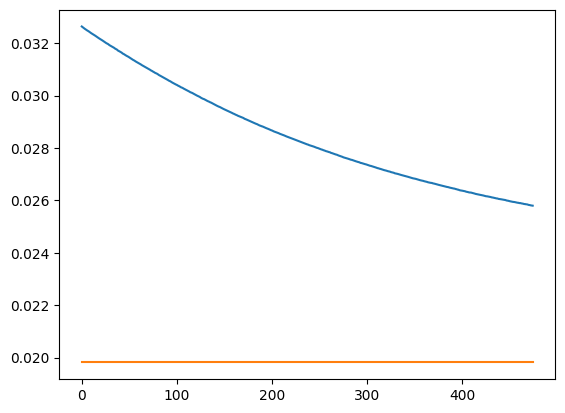

In [33]:
trivial_model_error= evaluate_model_on_dataset(evaluation_data,evaluation_targets,trivial_model)
print("trivial error:",trivial_model_error)
shortened_error_list = error_list[len(error_list)//20:]
plt.plot(shortened_error_list)
plt.plot(trivial_model_error*np.ones(len(shortened_error_list)))
plt.show()

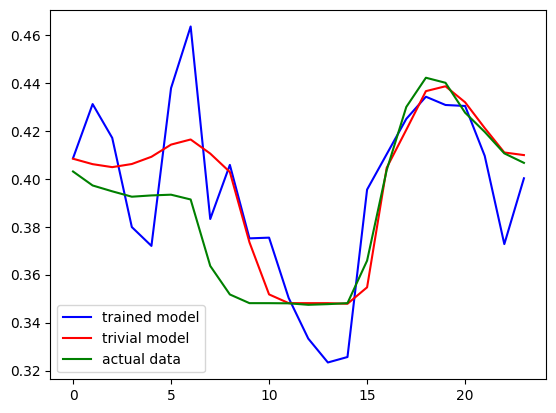

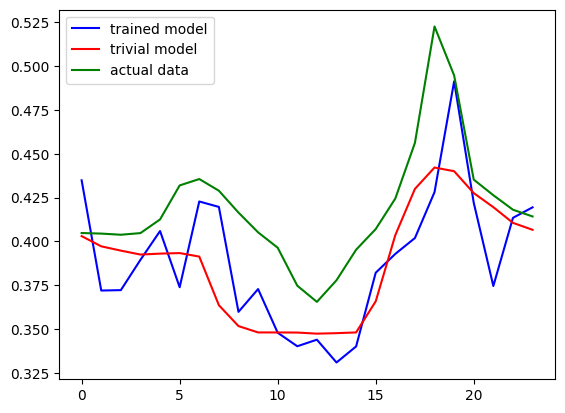

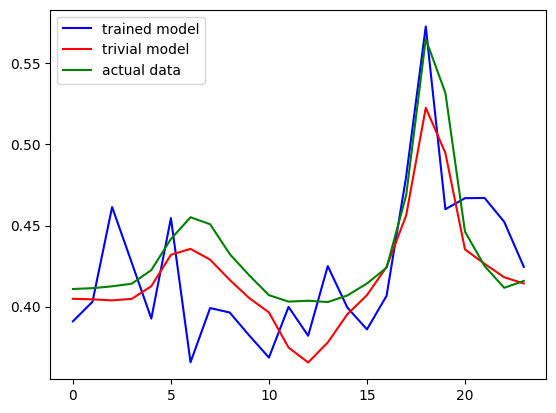

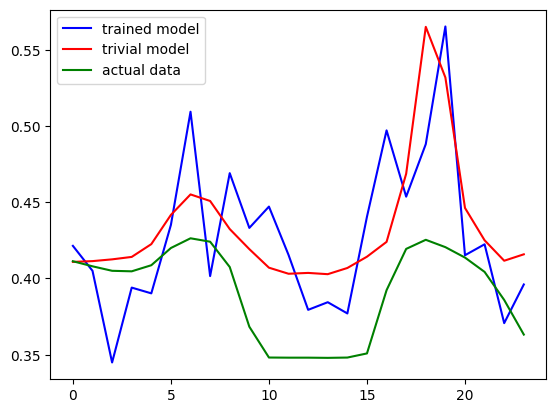

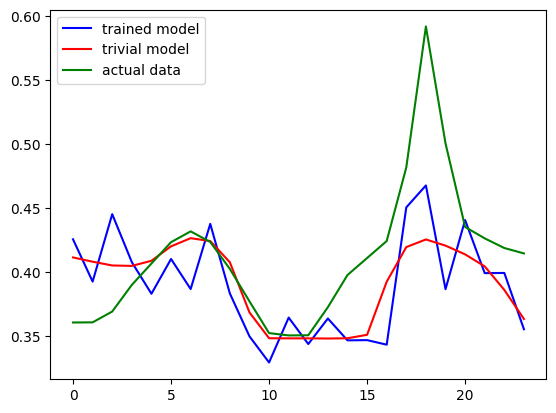

In [34]:
for index in range(5):
    with torch.no_grad():
        model_result = model(evaluation_data[index])
    trivial_result = trivial_model(evaluation_data[index])
    plt.plot(model_result,'b',label = "trained model")
    plt.plot(trivial_result,'r',label="trivial model")
    plt.plot(evaluation_targets[index],'g',label="actual data")
    plt.legend()
    plt.show()

So far it seems like our ML model is still inferior to the trivial model. Let's try and simplify it even further.

# Even easier model with only 3 datapoints

Let's make an even easier model that just outputs three different values: The price at 8am, 1pm and 7pm

In [35]:
filterthree = (8*np.ones(24) == np.array(range(24))) + (13*np.ones(24) == np.array(range(24))) + (19*np.ones(24) == np.array(range(24)))
filterthree

array([False, False, False, False, False, False, False, False,  True,
       False, False, False, False,  True, False, False, False, False,
       False,  True, False, False, False, False])

In [36]:
training_targets_3 = training_targets[:,filterthree]
evaluation_targets_3 = evaluation_targets[:,filterthree]
training_targets_3

tensor([[0.4727, 0.4732, 0.4727],
        [0.4383, 0.4155, 0.4426],
        [0.5075, 0.4938, 0.5190],
        ...,
        [0.4330, 0.4184, 0.4548],
        [0.4250, 0.3896, 0.4292],
        [0.4028, 0.3481, 0.4386]])

In [37]:
class three_time_predictor(nn.Module):
    def __init__(self, source_dim, the_filter=filterthree):
        super(three_time_predictor, self).__init__()
        self.input_linear = nn.Linear(source_dim, 3)
        self.the_filter= the_filter
        #self.activation = nn.ReLU()
        #self.correction_linear = nn.Linear(hidden_dim, 24)
    def forward(self, input):
            prediction = self.input_linear(input)#+input[...,3:3+24][...,self.the_filter]
            return prediction

In [38]:
data_dimensionality = len(training_data[0])

model_3 = three_time_predictor(data_dimensionality)
loss_function = nn.L1Loss() 
optimizer = torch.optim.SGD(model_3.parameters())
error_list = [] # list the keeps track of the mean absolute error of different training steps

In [39]:
training_dataset_incl_targets = torch.cat((training_data, training_targets_3) , -1)

In [40]:
train_dataloader = DataLoader(training_dataset_incl_targets, batch_size=64, shuffle=True)

In [41]:
model_3(evaluation_data[0])

tensor([ 0.2545, -0.6127,  0.1256], grad_fn=<ViewBackward0>)

In [42]:
EPOCH_NUMBER = 3000
model_3.train()
for epoch in range(EPOCH_NUMBER): 
    if not epoch%100:
        print("Epoch: "+str(epoch+1)+"/"+str(EPOCH_NUMBER))
    for databatch in train_dataloader:
        given = databatch[:,:-3]
        target = databatch[:,-3:]
        model_3.zero_grad()
        prediction = model_3(given)
        loss = loss_function(prediction, target)
        loss.backward()
        optimizer.step()
    mean_error = evaluate_model_on_dataset(evaluation_data,evaluation_targets_3,model_3)
    if not epoch%100:
        print("Mean absolute error:"+str(float(mean_error)))
    error_list.append(mean_error)
    if error_list[-1] > error_list[int(len(error_list)/2)]+0.03 or error_list[-1] > error_list[int(999*len(error_list)/1000)]+0.03:
        print("Training makes the fit significantly worse, aborting")
        break
print("Finished")

Epoch: 1/3000
Mean absolute error:0.27512158338840187
Epoch: 101/3000
Mean absolute error:0.03231817569870217
Epoch: 201/3000
Mean absolute error:0.02977219244444764
Epoch: 301/3000
Mean absolute error:0.028497711410780092
Epoch: 401/3000
Mean absolute error:0.02739807536259239
Epoch: 501/3000
Mean absolute error:0.026699592465118608
Epoch: 601/3000
Mean absolute error:0.026020366998710055
Epoch: 701/3000
Mean absolute error:0.025367346261338013
Epoch: 801/3000
Mean absolute error:0.02497010403773287
Epoch: 901/3000
Mean absolute error:0.024621523248079508
Epoch: 1001/3000
Mean absolute error:0.02435112276520483
Epoch: 1101/3000
Mean absolute error:0.02406119257757517
Epoch: 1201/3000
Mean absolute error:0.023477005107062195
Epoch: 1301/3000
Mean absolute error:0.023739195923447184
Epoch: 1401/3000
Mean absolute error:0.022963095238029776
Epoch: 1501/3000
Mean absolute error:0.02295918477487651
Epoch: 1601/3000
Mean absolute error:0.022666412586475906
Epoch: 1701/3000
Mean absolute err

In [43]:
def trivial_model_3(input_data):
    return input_data[3:3+24][filterthree]

trivial error: 0.025755140889476936


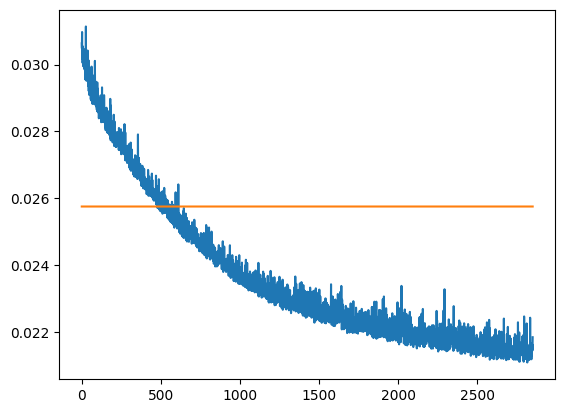

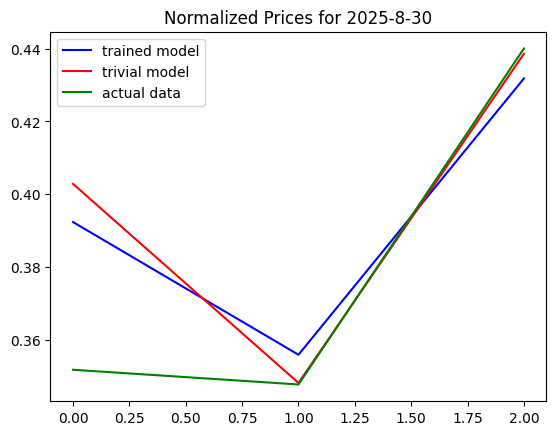

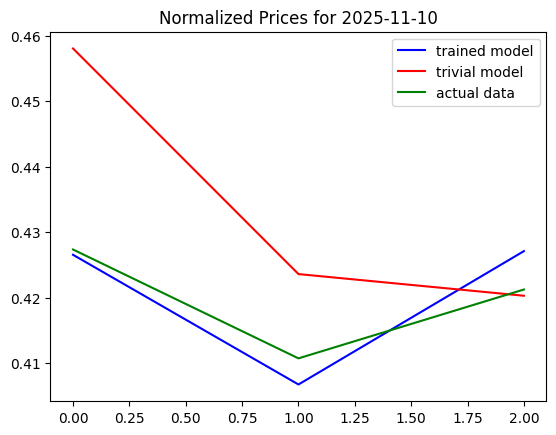

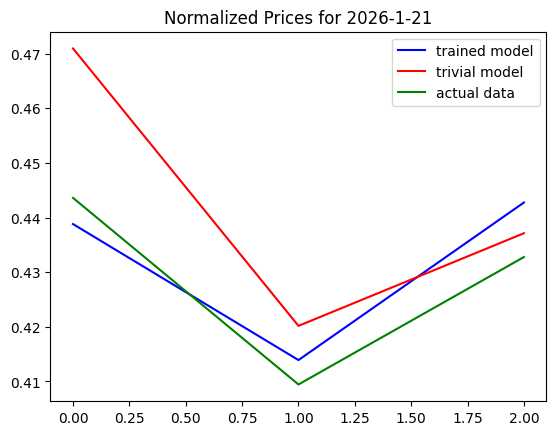

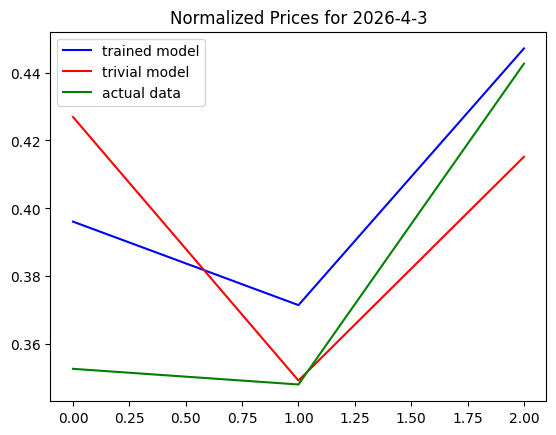

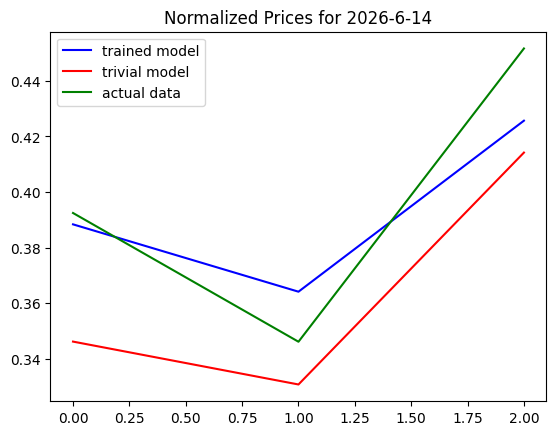

In [44]:
trivial_model_error= evaluate_model_on_dataset(evaluation_data,evaluation_targets_3,trivial_model_3)
print("trivial error:",trivial_model_error)
shortened_error_list = error_list[len(error_list)//20:]
plt.plot(shortened_error_list)
plt.plot(trivial_model_error*np.ones(len(shortened_error_list)))
plt.show()
for i in range(5):
    index = len(evaluation_data)//5*i
    with torch.no_grad():
        model_result = model_3(evaluation_data[index])
    trivial_result = trivial_model_3(evaluation_data[index])
    plt.plot(model_result,'b',label = "trained model")
    plt.plot(trivial_result,'r',label="trivial model")
    plt.plot(evaluation_targets_3[index],'g',label="actual data")
    plt.legend()
    year = int(evaluation_data[index][0]*10000)
    month =int(evaluation_data[index][1]*100)
    day = int(evaluation_data[index][2]*100)
    plt.title("Normalized Prices for "+str(year)+"-"+str(month)+"-"+str(day))
    plt.show()

Since the three-model seems to be better than the trivial three model, let's see if we can combine it with the trivial model to become better than the trivial model. For this we will add the three values multiplied by hat functions to the trivial_prediction

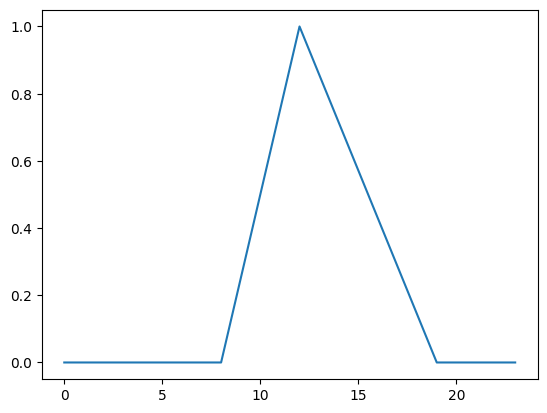

(np.float64(0.0), 24)

In [45]:
def linear_centered(markpoints, index_in_markpoints):
    ''' Creates a linear hat hat that is 1 at the markpoint of the index_in_markpoints, linear to the neighbouring markpoints and zero everywhere else'''
    markpoints_real = [markpoints[0]]+list(markpoints)+[markpoints[-1]+1] # Repeat the first and last entry for boundary behaviour
    index_in_markpoints_real = index_in_markpoints+1
    interval_left= markpoints_real[index_in_markpoints_real]-markpoints_real[index_in_markpoints_real-1]
    interval_right= markpoints_real[index_in_markpoints_real+1]-markpoints_real[index_in_markpoints_real]
    left_horizon = np.zeros(markpoints_real[index_in_markpoints_real-1])
    left_hat = np.arange(interval_left)/interval_left
    right_hat = np.ones(interval_right)-np.arange(interval_right)/interval_right
    right_horizon = np.zeros(markpoints_real[-1]-markpoints_real[index_in_markpoints_real+1])
    return np.concatenate((left_horizon,left_hat,right_hat,right_horizon))
hat = linear_centered((0,8,12,19,23),2)
plt.plot(hat)
plt.show()
hat[8],len(hat)

In [46]:
relevant_times = (0,8,12,19,23)

def corrected_trivial_prediction(input):
    with torch.no_grad():
        three_outputs = model_3(input)
    trivial_prediction = trivial_model(input)
    prediction = trivial_prediction
    #also correct the electricity price to start at the same price as yesterday's price ended
    four_better_knowledge = torch.cat((torch.tensor([trivial_prediction[-1]]),three_outputs))
    for i in range(len(three_outputs)):
        correction = torch.tensor(linear_centered(relevant_times,i)) * (four_better_knowledge[i]-trivial_prediction[relevant_times[i]])
        prediction = prediction+correction
    return prediction

prediction = corrected_trivial_prediction(evaluation_data[0])

In [47]:
trivial_model_error= evaluate_model_on_dataset(evaluation_data,evaluation_targets,trivial_model)
this_model_error = evaluate_model_on_dataset(evaluation_data,evaluation_targets,corrected_trivial_prediction)
print("Trivial error:", trivial_model_error)
print("This model's error:", this_model_error)

Trivial error: 0.01981651392038707
This model's error: 0.017377805551146465


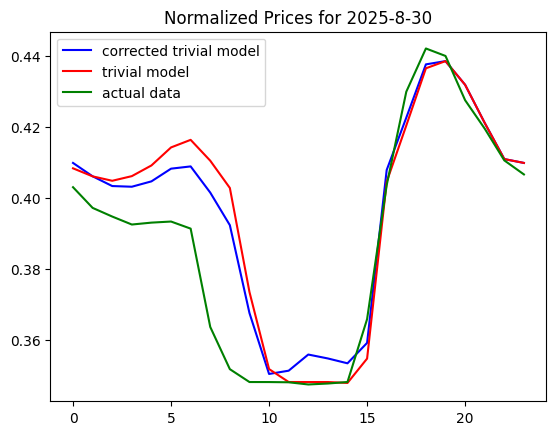

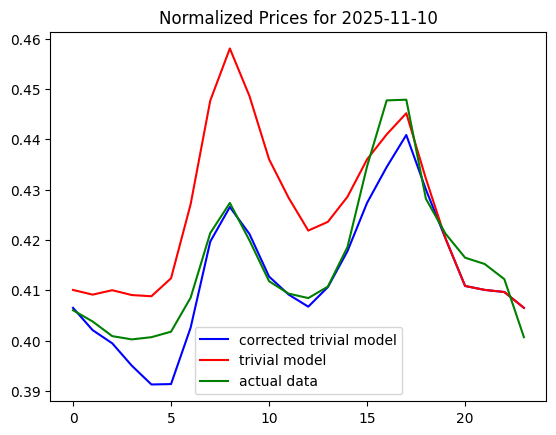

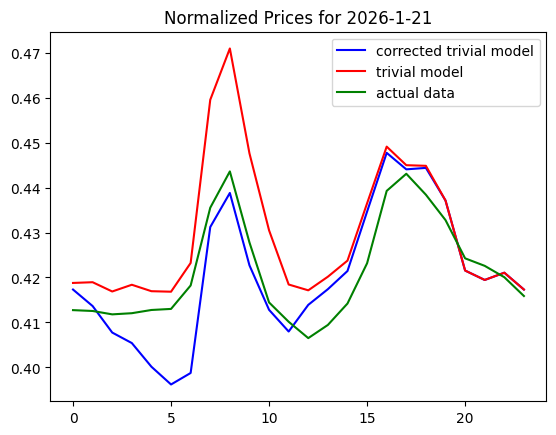

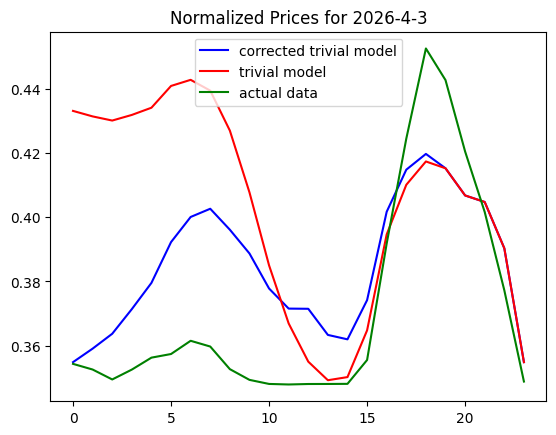

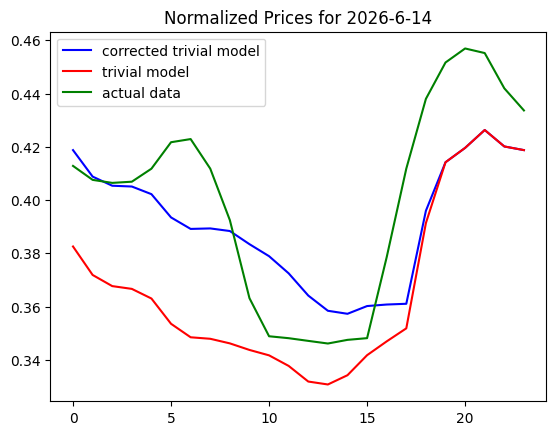

In [48]:
for i in range(5):
    index = len(evaluation_data)//5*i
    with torch.no_grad():
        model_result = corrected_trivial_prediction(evaluation_data[index])
    trivial_result = trivial_model(evaluation_data[index])
    plt.plot(model_result,'b',label = "corrected trivial model")
    plt.plot(trivial_result,'r',label="trivial model")
    plt.plot(evaluation_targets[index],'g',label="actual data")
    plt.legend()
    year = int(evaluation_data[index][0]*10000)
    month =int(evaluation_data[index][1]*100)
    day = int(evaluation_data[index][2]*100)
    plt.title("Normalized Prices for "+str(year)+"-"+str(month)+"-"+str(day))
    plt.show()

/tmp/ipykernel_84226/1572950383.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  scalar_error_trivial_model = np.dot( error_trivial_model , torch.ones(len(error_trivial_model)) ) /len(error_trivial_model)
/tmp/ipykernel_84226/1572950383.py:9: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  scalar_error_corrected_model = np.dot( error_corrected_model , torch.ones(len(error_trivial_model)) ) /len(error_corrected_model)


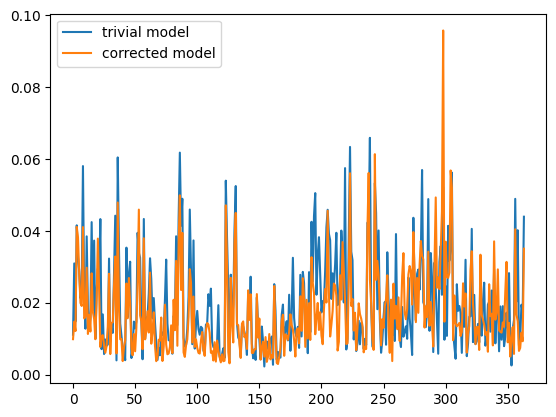

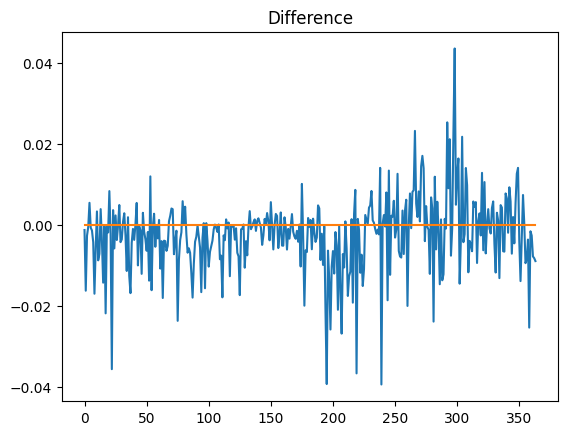

The graphs show the interval after  2025 - 8 - 30


In [49]:
errorlist_trivial_model =[]
errorlist_corrected_model =[]
for i,datum in enumerate(evaluation_data):
    error_trivial_model = torch.abs(trivial_model(datum)-evaluation_targets[i])
    scalar_error_trivial_model = np.dot( error_trivial_model , torch.ones(len(error_trivial_model)) ) /len(error_trivial_model)
    errorlist_trivial_model.append(float(scalar_error_trivial_model))
    #same for the corrected model
    error_corrected_model = torch.abs(corrected_trivial_prediction(datum)-evaluation_targets[i])
    scalar_error_corrected_model = np.dot( error_corrected_model , torch.ones(len(error_trivial_model)) ) /len(error_corrected_model)
    errorlist_corrected_model.append(float(scalar_error_corrected_model))
plotted_errorlist_trivial_model = errorlist_trivial_model[:365]
plotted_errorlist_corrected_model = errorlist_corrected_model[:365]
plt.plot(plotted_errorlist_trivial_model,label = "trivial model")
plt.plot(plotted_errorlist_corrected_model, label="corrected model")
plt.legend()
plt.show()
plt.title('Difference')
plt.plot(np.array(plotted_errorlist_corrected_model)-np.array(plotted_errorlist_trivial_model))
plt.plot(np.zeros(len(plotted_errorlist_trivial_model)))
plt.show()
print("The graphs show the interval after ",int(evaluation_data[0,0]*10000),"-",int(evaluation_data[0,1]*100),"-",int(evaluation_data[0,2]*100))

# Month by Month analysis

This seems like the corrected model performs only superior in summer, but not in winter. Let's check this by filtering for dates in certain months.

Normalized prices on 2026 - 7 - 1


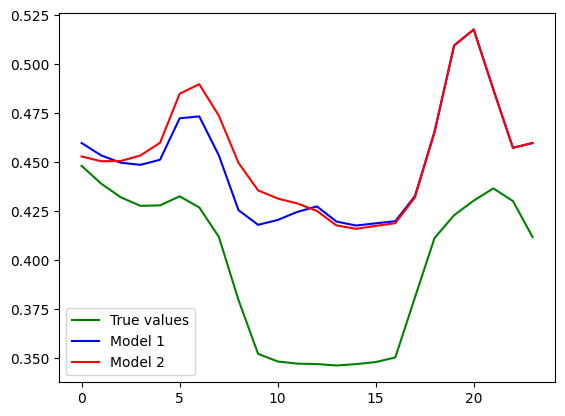

(0.01737780542321752, 0.01981651392038707)

In [50]:
def visually_compare_models(mod1, mod2,data_filter = (evaluation_data[:,0]==evaluation_data[:,0]), name1 = "Model 1", name2= "Model 2"):
    dataset = evaluation_data[data_filter]
    targetset = evaluation_targets[data_filter]
    plotting_index = int(np.random.random()*len(targetset))
    print("Normalized prices on",int(dataset[plotting_index][0]*10000),"-",int(dataset[plotting_index][1]*100),"-",int(dataset[plotting_index][2]*100))
    plt.plot(targetset[plotting_index],"g",label="True values")
    plt.plot(mod1(dataset[plotting_index]),"b",label = name1)
    plt.plot(mod2(dataset[plotting_index]),"r",label = name2)
    plt.legend()
    plt.show()
    error_1 = evaluate_model_on_dataset(dataset,targetset,mod1)
    error_2 = evaluate_model_on_dataset(dataset,targetset,mod2)
    return error_1, error_2
visually_compare_models(corrected_trivial_prediction, trivial_model)

In [51]:
month_tensor = torch.arange(12)+torch.ones(12)
month_tensor

tensor([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.])

we unfortunately can't filter for the month entry to be equal to the month number, because equations of floats are badly behaved. This is why we do inequalities. The multiplication * is just the binary "and"

In [52]:
month_filters = []
for i in month_tensor:
    month_filter = (evaluation_data[:,1] > 0.005*i* torch.ones(len(evaluation_data))) * (evaluation_data[:,1] < 0.015*i* torch.ones(len(evaluation_data)))
    month_filters.append(month_filter)

Comparison for month 1
Normalized prices on 2026 - 1 - 21


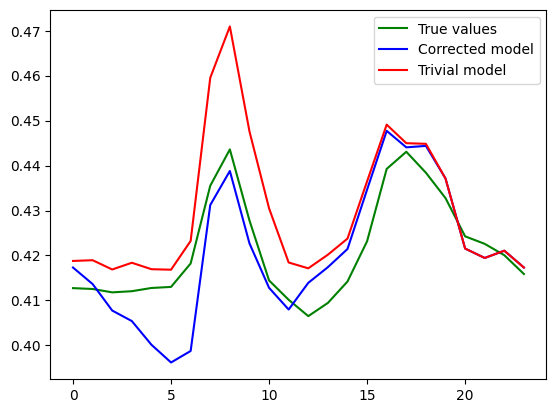

Corrected model error:  0.013920231736601313
Trivial model error: 0.015455791185940463


Comparison for month 2
Normalized prices on 2026 - 2 - 20


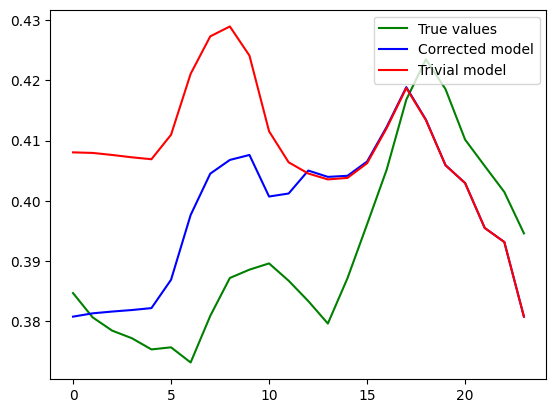

Corrected model error:  0.009717955128891632
Trivial model error: 0.012068275539647967


Comparison for month 3
Normalized prices on 2026 - 3 - 17


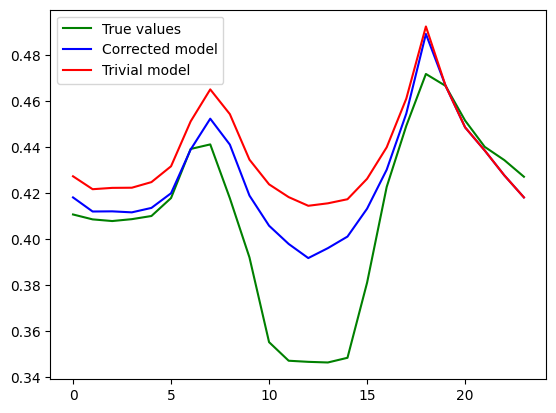

Corrected model error:  0.016789002819067277
Trivial model error: 0.02181437775520573


Comparison for month 4
Normalized prices on 2026 - 3 - 16


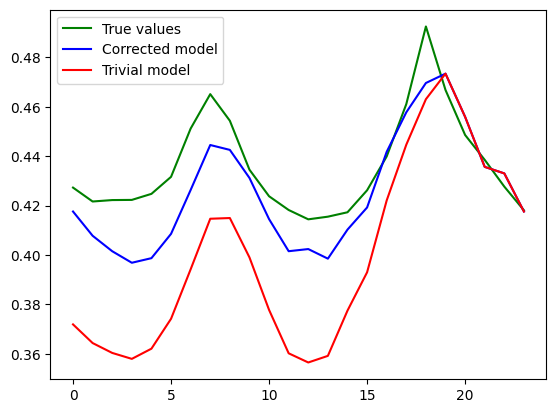

Corrected model error:  0.020133212019640755
Trivial model error: 0.023515033279208165


Comparison for month 5
Normalized prices on 2026 - 4 - 24


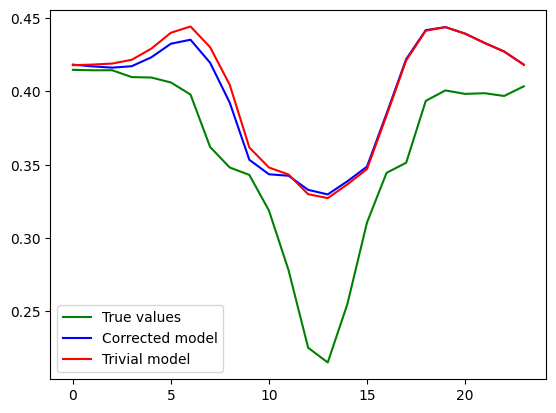

Corrected model error:  0.021358671238333175
Trivial model error: 0.02272876060703741


Comparison for month 6
Normalized prices on 2026 - 5 - 26


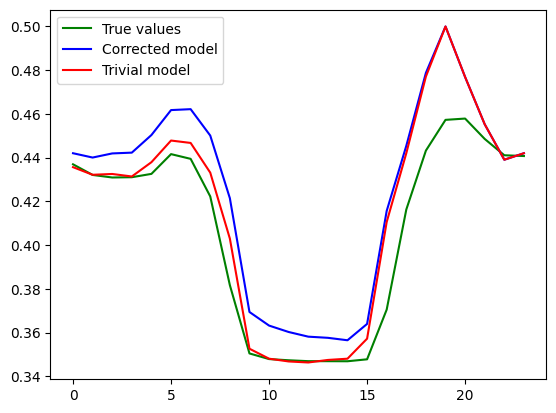

Corrected model error:  0.02086119105147272
Trivial model error: 0.02080161908739492


Comparison for month 7
Normalized prices on 2026 - 6 - 3


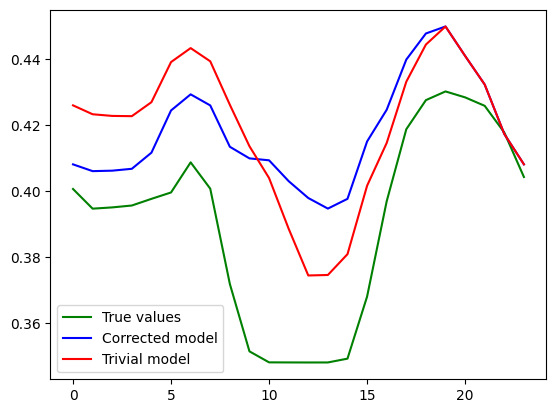

Corrected model error:  0.020110883044336513
Trivial model error: 0.021128002629966624


Comparison for month 8
Normalized prices on 2025 - 9 - 28


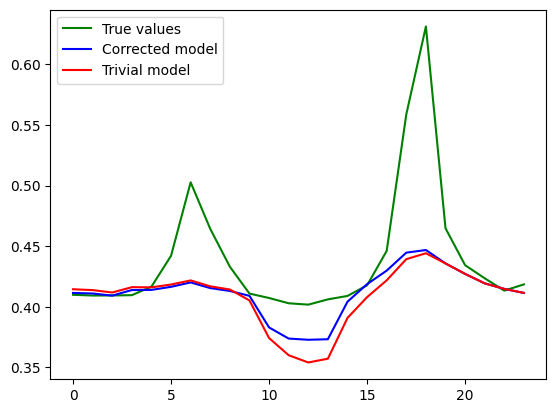

Corrected model error:  0.01906666158408702
Trivial model error: 0.020269291877676638


Comparison for month 9
Normalized prices on 2026 - 6 - 29


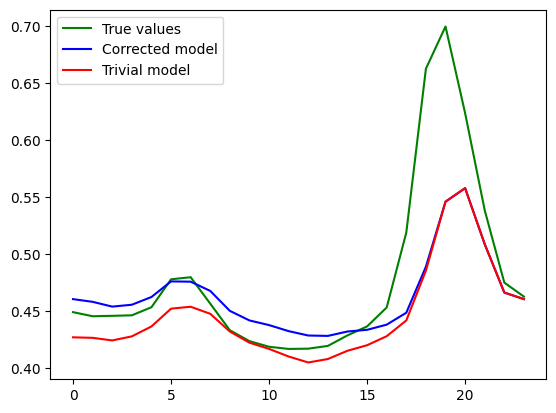

Corrected model error:  0.01803185524618729
Trivial model error: 0.019641811147718964


Comparison for month 10
Normalized prices on 2026 - 7 - 5


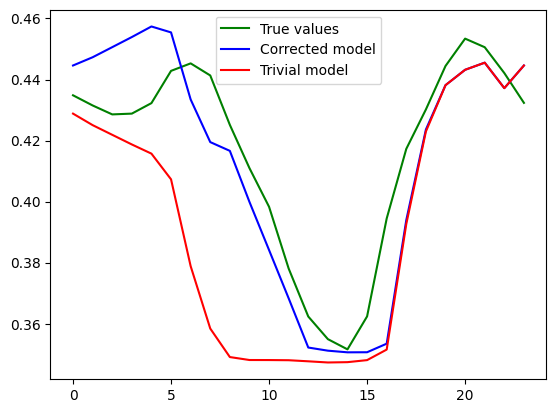

Corrected model error:  0.01803185524618729
Trivial model error: 0.019641811147718964


Comparison for month 11
Normalized prices on 2026 - 8 - 11


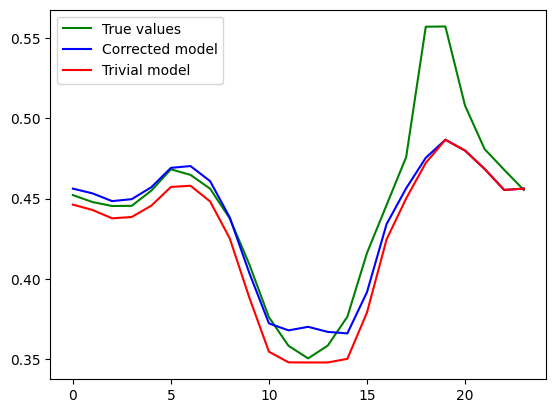

Corrected model error:  0.017697820032051656
Trivial model error: 0.019872238326100678


Comparison for month 12
Normalized prices on 2026 - 8 - 16


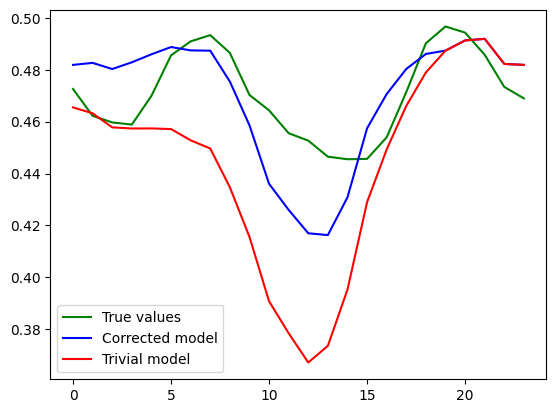

Corrected model error:  0.01578630265158669
Trivial model error: 0.01887506995017628




In [53]:
error_list_model = []
error_list_trivial = []
for i, month_filter in enumerate(month_filters):
    print("Comparison for month" , i+1)
    error_prediction, error_trivial = visually_compare_models(corrected_trivial_prediction, trivial_model, data_filter=month_filter,name1="Corrected model",name2="Trivial model")
    print("Corrected model error: ",error_prediction)
    print("Trivial model error:", error_trivial)
    error_list_model.append(error_prediction)
    error_list_trivial.append(error_trivial)
    print("\n")

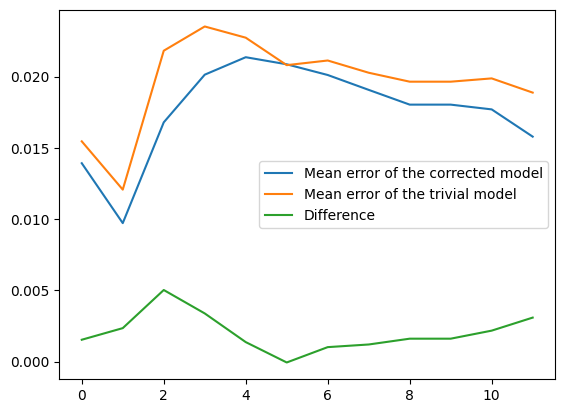

In [54]:
plt.plot(error_list_model,label="Mean error of the corrected model")
plt.plot(error_list_trivial,label = "Mean error of the trivial model")
plt.plot(-np.array(error_list_model)+np.array(error_list_trivial), label = "Difference")
plt.legend()
plt.show()

# Are the improvements over the trivial model statistically significant?
Disclaimer: We will do a T-test here, but we are aware that we are not following good statistical practice, so the result won't be significant on a scientific level. The issue is that we don't have separate evaluation data and test data. Thus the choice of model includes biases introduced by the evaluation data. Nevertheless, it is still interesting to see if we get a significant p-value

In [55]:
import scipy.stats as stats

In [56]:
error_list_trivial_daywise = []
error_list_corrected_daywise = []
for i,datum in enumerate(evaluation_data):
    errors_trivial = torch.abs(evaluation_targets[i]- trivial_model(datum))
    trivial_error_today = float(torch.sum(errors_trivial)) /24
    error_list_trivial_daywise.append(trivial_error_today)
    errors_corrected = torch.abs(evaluation_targets[i]- corrected_trivial_prediction(datum))
    corrected_error_today = float(torch.sum(errors_corrected)) /24
    error_list_corrected_daywise.append(corrected_error_today)


In [57]:
T, p = stats.ttest_ind(error_list_trivial_daywise, error_list_corrected_daywise)

In [58]:
T, p

(np.float64(2.6095271793932593), np.float64(0.009253512749702585))

So, with the caveats mentioned earlier, we have more than 3 standard deviations of difference and a p-value less than 5%. This strongly indicates (though not scientifically proves) that the corrected model is actually better than the trivial model.

# De-normalizing the output
For completeness and usability, we create a single function that includes the corrected model and de-normalizes the output value. For an actual application, we would need to put things together, so normalization, prediction and de-normalization happen in one step.

In [59]:
de_normalized_model = lambda x : de_normalize_price(corrected_trivial_prediction(x))
de_normalized_trivial_model = lambda x : de_normalize_price(trivial_model(x))
de_normalized_targets = de_normalize_price(evaluation_targets)

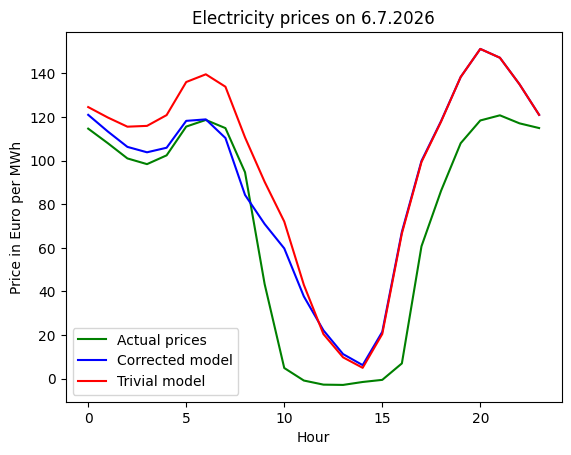

In [60]:
random_day_index = int(np.random.random()*len(de_normalized_targets))
title_text = "Electricity prices on " + str(int(evaluation_data[random_day_index,2]*101)) + "." + str(int(evaluation_data[random_day_index,1]*101)) + "." +str(int(evaluation_data[random_day_index,0]*10001))
fig = plt.figure()
plt.title(title_text)
plt.plot(de_normalize_price(evaluation_targets[random_day_index]),"g",label="Actual prices")
plt.plot(de_normalized_model(evaluation_data[random_day_index]),'b',label="Corrected model")
plt.plot(de_normalized_trivial_model(evaluation_data[random_day_index]),'r',label="Trivial model")
plt.xlabel("Hour")
plt.ylabel("Price in Euro per MWh")
plt.legend()
plt.show()

In [61]:
fig.savefig('price_curve.png', bbox_inches='tight')